# Dissolution and pH over time

Plot two supplementary figures, pulling in data from `postproc/<tag>/point.zarr` and `postproc/<tag>/dissolution.zarr`.

1. Weathering fraction and porewater pH against **years since first application**. Uses area-weighted mean with a 10-90th percentile band.
2. Time-mean CDR flux against the pH change from the model's initial soil pH.

The weathering fraction comes from the model's mineral tracking (not carbon or alk fluxes).

Set `CASE` to `"1gt"` or `"2gt"`. 

In [1]:
import warnings; warnings.filterwarnings("ignore")
import os
import numpy as np, xarray as xr
import matplotlib as mpl, matplotlib.pyplot as plt
import cmocean

CASE     = "1gt"                                        # "1gt" or "2gt"
TAG      = {"1gt": "e0-conus-1gt", "2gt": "e0-conus-2gt"}[CASE]
ROOT     = "s3://carbonplan-carbon-removal/ew-workflows-data/beerling-2025-model-extension"
POSTPROC = os.environ.get("BEERLING_POSTPROC", f"{ROOT}/postproc/{TAG}")

# ---- design, shared by every fx-* figure notebook -------------------
THEME = "haline"        # "balance" | "haline" | "dense"
cm = cmocean.cm
THEMES = dict(                        #  E0            /    other
    balance=(cm.balance(.18), cm.balance(.82), cm.balance(.82)), #, cm.dense(.62)),   # blue / red / violet
    haline =(cm.haline(.35),  cm.solar(.55), cm.solar(.55)), #     cm.solar(.55)),   # teal / brick / gold
    dense  =(cm.dense(.50),   cm.solar(.60), cm.solar(.60)) #,   cm.algae(.50)),   # violet / gold / green
)
C = dict(zip(("e0", "e1", "e2"), THEMES[THEME]))
C.update(published="0.35", ctrl="0.60", ink="0.15", muted="0.45")
C["req"] = C["e1"]
W = dict(col1=3.42, col15=4.49, col2=7.05)   # in: PNAS 1 / 1.5 / 2-column

mpl.rcParams.update({
    "figure.dpi": 140, "savefig.dpi": 600, "figure.facecolor": "white",
    "pdf.fonttype": 42, "ps.fonttype": 42,       # TrueType; journals reject Type 3
    "font.family": "sans-serif",
    "font.sans-serif": ["Helvetica Neue", "Helvetica", "Arial", "DejaVu Sans"],
    "font.size": 9.5, "text.color": C["ink"], "axes.labelcolor": C["ink"],
    "axes.labelsize": 10.5, "axes.titlesize": 10.5, "axes.titleweight": "regular",
    "axes.titlelocation": "left", "xtick.labelsize": 9.5, "ytick.labelsize": 9.5,
    "legend.fontsize": 9.5, "axes.linewidth": 0.9, "axes.edgecolor": "0.25",
    "axes.grid": False, "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": "0.25", "ytick.color": "0.25",
    "xtick.labelcolor": C["ink"], "ytick.labelcolor": C["ink"],
    "xtick.major.width": 0.9, "ytick.major.width": 0.9,
    "xtick.major.size": 3.6, "ytick.major.size": 3.6,
    "xtick.minor.width": 0.7, "ytick.minor.width": 0.7,
    "xtick.minor.size": 2.0, "ytick.minor.size": 2.0,
    "legend.frameon": False, "legend.handlelength": 1.3, "legend.borderpad": 0.0,
    "legend.handletextpad": 0.55, "legend.labelspacing": 0.40, "lines.linewidth": 1.8,
})

def save(fig, stem):
    os.makedirs("panels", exist_ok=True)
    for ext in ("png", "pdf"):
        fig.savefig(f"panels/{stem}.{ext}", bbox_inches="tight", pad_inches=.02)

def wq(x, w, p):
    """Weighted quantile, linear interpolation on the midpoint CDF."""
    o = np.argsort(x); x, w = x[o], w[o]
    return np.interp(p, (np.cumsum(w) - .5 * w) / w.sum(), x)

M_CO2 = 44.009        # g/mol
G2T   = 0.01          # 1 g/m2 = 0.01 t/ha

pt  = xr.open_zarr(f"{POSTPROC}/point.zarr").load()
dis = xr.open_zarr(f"{POSTPROC}/dissolution.zarr").load()
YRS = pt.time.values.astype(int)
SY  = pt.start_year.values.astype(int)
AR  = pt.area_ha.values
NYR = 2070 - SY + 1                  # years of application, first year inclusive

def per_point(v):
    """A (cluster, feedstock) field mixed at w onto points, exactly as point.zarr is."""
    a = (dis[v].sel(cluster=pt.cluster.values).drop_vars("cluster")
            .rename(cluster="point").assign_coords(point=pt.point))
    return pt.w * a.sel(feedstock=1) + (1 - pt.w) * a.sel(feedstock=2)

def dif(a):
    """Year-on-year increment of a cumulative field, NaN kept outside the run."""
    c = a.fillna(0.)
    return (c - c.shift(time=1, fill_value=0.)).where(a.notnull())

APPLIED   = per_point("applied_eq")                     # eq/m2, cumulative
DISSOLVED = APPLIED - per_point("locked_eq")

MODE = "cumulative"     # "cumulative" = of all rock applied so far | "annual" = of that year's application
WF = (DISSOLVED / APPLIED) if MODE == "cumulative" else (dif(DISSOLVED) / dif(APPLIED))

# Initial soil pH. inps.pH is a 7-layer CLM profile; mod5.m:157-166 interpolates it
# onto the 31-node 0-0.15 m column, so only the first three layers reach it.
CLM_DEPTHS = np.array([0, 5, 15, 30, 60, 100, 200]) / 100.
ZCOL = np.arange(0, .15 + 1e-9, .005)
PH_I = np.array([np.interp(ZCOL, CLM_DEPTHS, r).mean() for r in pt.pH0.values])

K = np.arange(-1, NYR.max())          # years since first application; -1 is pre-application

def align(a, pre=None):
    """Reindex a (point, time) field onto years since that point's first application.

    The runs begin in the application year, so the only pre-application value the
    model has is its own input: pass it as `pre` to fill k = -1."""
    A = np.full((pt.sizes["point"], len(K)), np.nan)
    A[:, 0] = np.nan if pre is None else pre
    for i, j0 in enumerate(SY - YRS[0]):
        n = min(len(K) - 1, len(YRS) - j0)
        A[i, 1:1 + n] = a[i, j0:j0 + n]
    return A

def band(A, ps=(.1, .9)):
    """Area-weighted mean, quantiles and area coverage down the point axis."""
    ok = np.isfinite(A); wm = np.where(ok, AR[:, None], 0.).sum(0)
    mean = np.nansum(np.where(ok, A, 0.) * AR[:, None], 0) / np.where(wm > 0, wm, np.nan)
    q = np.array([wq(A[ok[:, j], j], AR[ok[:, j]], ps) if ok[:, j].sum() > 1
                  else [np.nan] * len(ps) for j in range(A.shape[1])]).T
    return mean, q, wm / AR.sum()

print(f"{TAG}  S{int(str(pt.attrs['scenario']).lstrip('S'))}  {pt.sizes['point']:,} points  "
      f"{pt.cluster.to_series().nunique()} clusters  {AR.sum() / 1e6:.2f} M ha  "
      f"{YRS[0]}-{YRS[-1]}")
RCO2 = M_CO2 * APPLIED.sel(time=2070) / (pt.rock.sel(time=2070) / G2T)
print(f"feedstock ceiling {float(RCO2.min()):.3f}-{float(RCO2.max()):.3f} "
      f"t CO2/t rock at perfect dissolution")
print(f"weathering fraction, {MODE}: median {np.nanmedian(WF.values):.3f} over point-years")

e0-conus-1gt  S1  2,322 points  221 clusters  24.49 M ha  2020-2070
feedstock ceiling 0.401-0.491 t CO2/t rock at perfect dissolution
weathering fraction, cumulative: median 0.663 over point-years


## Figure — weathering fraction and pH since first application

Year `-1` is pre-application and uses `pH0`, the soil pH the model is initialised with. Panel **a** has no year `-1` because no rock has been applied yet.

Because we move the x-axis to be years since first rock application, only a handful of points have data spanning the full 50-year window. Consequently, with more years after initial application the number of deployed points decreases. To help our curves stay more representative, we remove the latest years where less than `MIN_AREA_FRAC` of total land used for EW is deployed (set to 5 percent by default). 

years since first application: -1 to 37 kept at >= 5% area coverage
weathering fraction, area-weighted mean   yr0 0.498   yr10 0.652   yr37 0.718
pH, area-weighted mean   initial 6.13   yr0 7.01   yr10 7.20   yr37 7.18


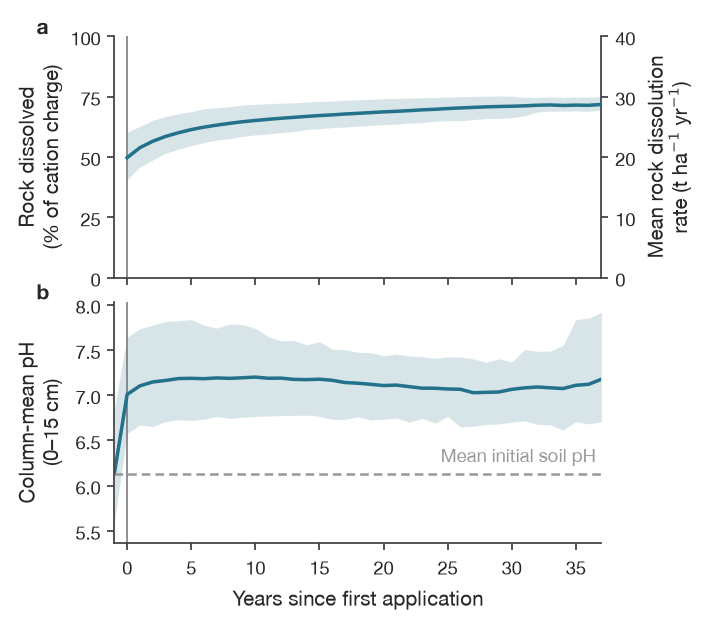

In [2]:
MIN_AREA_FRAC = 0.05

# Every point gets the same rock dose every year, so % of charge dissolved x RATE / 100 is an exact
# second reading in t rock/ha/yr (rock-mass equivalent of the charge released)
APP  = dif(pt.rock).values
APP  = APP[np.isfinite(APP)]                       # t rock/ha applied, each point-year
assert np.ptp(APP) < 1e-6, "application rate varies; % dissolved no longer maps 1:1 onto t/ha/yr"
RATE = float(APP.mean())                           # 40 t/ha/yr in both cases

wf_m, wf_q, _   = band(align(WF.values))
ph_m, ph_q, cov = band(align(pt.pH_col.values, pre=PH_I))   # pH0 fills k = -1
keep = cov >= MIN_AREA_FRAC
k = K[keep]
ok = np.isfinite(wf_m[keep])        # no rock is applied at k = -1, so no fraction there
phi0 = float(np.average(PH_I, weights=AR))
at = lambda a, kk: a[np.flatnonzero(K == kk)[0]]

print(f"years since first application: -1 to {k.max()} kept at >= {MIN_AREA_FRAC:.0%} area coverage")
print(f"weathering fraction, area-weighted mean   yr0 {at(wf_m, 0):.3f}   "
      f"yr10 {at(wf_m, 10):.3f}   yr{k.max()} {wf_m[keep][-1]:.3f}")
print(f"pH, area-weighted mean   initial {phi0:.2f}   yr0 {at(ph_m, 0):.2f}   "
      f"yr10 {at(ph_m, 10):.2f}   yr{k.max()} {ph_m[keep][-1]:.2f}")

fig, axes = plt.subplots(2, 1, sharex=True, figsize=(W["col15"], 4.7))
fig.subplots_adjust(hspace=.10)

ax = axes[0]
ax.fill_between(k[ok], wf_q[0][keep][ok] * 100, wf_q[1][keep][ok] * 100,
                color=C["e0"], alpha=.18, lw=0)
ax.plot(k[ok], wf_m[keep][ok] * 100, color=C["e0"], lw=1.8)
ax.set_ylim(0, 100)
ax.set_ylabel("Rock dissolved\n(% of cation charge)")
ax.yaxis.set_major_locator(mpl.ticker.MultipleLocator(25))
# "cumulative" is everything dissolved so far over the years elapsed: the mean rate since first
# application, which trails that year's rate while the fraction is still rising
rx = ax.secondary_yaxis("right", functions=(lambda p: p * RATE / 100, lambda t: t * 100 / RATE))
rx.set_ylabel(("Mean rock dissolution\nrate" if MODE == "cumulative" else "Rock dissolution\nrate")
              + " (t ha$^{-1}$ yr$^{-1}$)")
rx.yaxis.set_major_locator(mpl.ticker.MultipleLocator(RATE / 4))   # ticks line up with the % ones

ax = axes[1]
ax.fill_between(k, ph_q[0][keep], ph_q[1][keep], color=C["e0"], alpha=.18, lw=0)
ax.plot(k, ph_m[keep], color=C["e0"], lw=1.8)
ax.axhline(phi0, color=C["ctrl"], ls=(0, (3.4, 2.0)), lw=1.3)
ax.annotate("Mean initial soil pH", xy=(k.max(), phi0), xytext=(-3, 4),
            textcoords="offset points", color=C["ctrl"], fontsize=9.5,
            ha="right", va="bottom")
ax.set_ylim(min(phi0, np.nanmin(ph_q[0][keep])) - .22, None)
ax.set_ylabel("Column-mean pH\n(0–15 cm)")
ax.set_xlabel("Years since first application")
ax.set_xlim(-1, k.max())

for ax in axes:
    ax.axvline(0, color=C["muted"], lw=0.8, zorder=1)
for ax, L in zip(axes, "ab"):
    ax.annotate(L, xy=(0, 1), xycoords="axes fraction", xytext=(-40, 12),
                textcoords="offset points", fontweight="bold", fontsize=11,
                va="top", ha="left")
fig.align_ylabels(axes)

save(fig, f"diss-ph_{CASE}")

## Figure — CDR flux against the pH change

We use one marker per deployment point whose size reflects the total area it represents. 

The pH change is measured from the initial soil pH the model was handed to the mean of the last `min(10, n - 2)` years of that point's `n`-year deployment — the shortened window keeps the first two years out of the mean so we miss the initial dissolution ramp-up.

102 points (4.3% of area) get < 12 yr of application; their window is 3-9 yr
CDR flux, t CO2/ha/yr   area-wt median 8.84   (p5 7.03, p95 10.44)
dpH                     area-wt median +1.11   (p5 +0.89, p95 +1.37)
initial pH              area-wt median 6.07
correlation +0.34; 16 points (0.7% of area) end below their initial pH


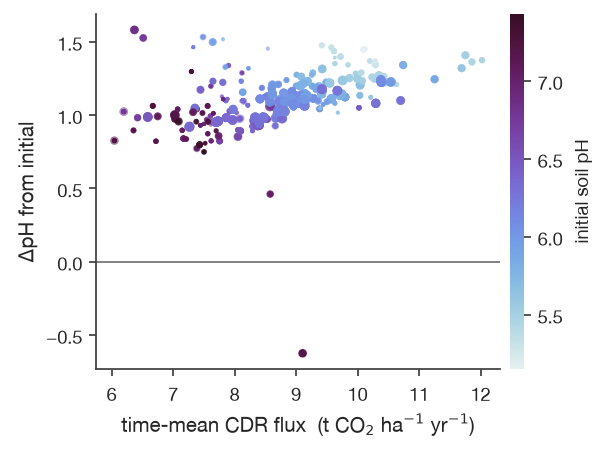

In [7]:
CDR_VAR = "cdr"          # export + pedogenic carbonate, the whole flux raised in the soil

NW  = np.minimum(10, NYR - 2)                 # >= 2 yr after onset, at most the last 10
PHF = np.array([np.nanmean(pt.pH_col.values[i, YRS >= 2071 - NW[i]])
                for i in range(pt.sizes["point"])])
DPH = PHF - PH_I
FLX = pt[CDR_VAR].sel(time=2070).values / NYR                  # t CO2/ha/yr, time mean

print(f"{int((NYR < 12).sum()):,} points ({AR[NYR < 12].sum() / AR.sum():.1%} of area) get "
      f"< 12 yr of application; their window is {NW[NYR < 12].min()}-{NW[NYR < 12].max()} yr")
print(f"CDR flux, t CO2/ha/yr   area-wt median {wq(FLX, AR, .5):.2f}   "
      f"(p5 {wq(FLX, AR, .05):.2f}, p95 {wq(FLX, AR, .95):.2f})")
print(f"dpH                     area-wt median {wq(DPH, AR, .5):+.2f}   "
      f"(p5 {wq(DPH, AR, .05):+.2f}, p95 {wq(DPH, AR, .95):+.2f})")
print(f"initial pH              area-wt median {wq(PH_I, AR, .5):.2f}")
print(f"correlation {np.corrcoef(FLX, DPH)[0, 1]:+.2f}; "
      f"{int((DPH < 0).sum())} points ({AR[DPH < 0].sum() / AR.sum():.1%} of area) end below "
      f"their initial pH")

fig, ax = plt.subplots(figsize=(W["col15"], 3.3))
s = ax.scatter(FLX, DPH, s=np.clip(AR / AR.mean() * 11, 2, 110), c=PH_I,
               cmap=cm.dense, alpha=.55, lw=0, zorder=3)
ax.axhline(0, color=C["muted"], lw=0.9, zorder=2)
ax.set_xlabel("time-mean CDR flux  (t CO$_2$ ha$^{-1}$ yr$^{-1}$)")
ax.set_ylabel("$\\Delta$pH from initial")
cb = fig.colorbar(s, ax=ax, pad=.02, aspect=26)
cb.set_label("initial soil pH", fontsize=9.5)
cb.outline.set_visible(False)
cb.solids.set_alpha(1)

save(fig, f"cdr-dph_{CASE}")

In [ ]:
# ---